In [1]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)

Python version: 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]
Python location: C:\Users\BSES\anaconda3\envs\supplychain\python.exe


In [2]:
import os

print(os.listdir(".."))

['dashboard', 'data', 'documentation', 'notebooks', 'outputs', 'README.md', 'src']


In [3]:
import os

data_path = "../data"

files = os.listdir(data_path)

print("Total files:", len(files))
print("\nDataset files:")

for file in files:
    print(file)

Total files: 9

Dataset files:
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [4]:
import pandas as pd

orders = pd.read_csv("../data/olist_orders_dataset.csv")

print("Dataset shape:", orders.shape)

orders.head()

Dataset shape: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
print("Missing values in each column:")
print(orders.isnull().sum())

print("\nOrder status counts:")
print(orders["order_status"].value_counts())

Missing values in each column:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [6]:
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"]
)

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

print("Average delivery time:", round(delivered_orders["delivery_days"].mean(), 2), "days")
print("Minimum delivery time:", round(delivered_orders["delivery_days"].min(), 2), "days")
print("Maximum delivery time:", round(delivered_orders["delivery_days"].max(), 2), "days")

Average delivery time: 12.56 days
Minimum delivery time: 0.53 days
Maximum delivery time: 209.63 days


In [7]:
print("Median delivery time:",
      round(delivered_orders["delivery_days"].median(), 2), "days")

print("\nDelivery time summary:")
print(delivered_orders["delivery_days"].describe())

Median delivery time: 10.22 days

Delivery time summary:
count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_days, dtype: float64


In [8]:
delivered_orders["order_estimated_delivery_date"] = pd.to_datetime(
    delivered_orders["order_estimated_delivery_date"]
)

delivered_orders["delay_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivered_orders["late_delivery"] = (
    delivered_orders["delay_days"] > 0
)

print("Late orders:",
      delivered_orders["late_delivery"].sum())

print("On-time or early orders:",
      (~delivered_orders["late_delivery"]).sum())

print("Late delivery percentage:",
      round(delivered_orders["late_delivery"].mean() * 100, 2), "%")

Late orders: 7826
On-time or early orders: 88652
Late delivery percentage: 8.11 %


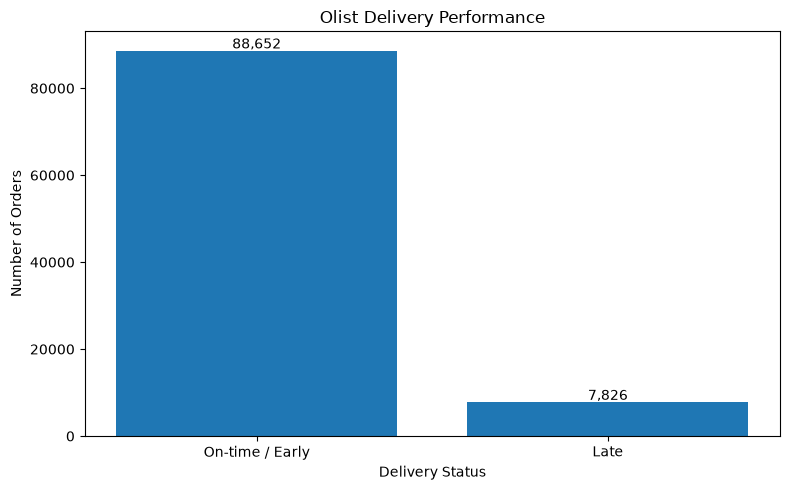

In [9]:
import matplotlib.pyplot as plt

late_counts = delivered_orders["late_delivery"].value_counts()

labels = ["On-time / Early", "Late"]
values = [
    late_counts.get(False, 0),
    late_counts.get(True, 0)
]

plt.figure(figsize=(8, 5))
plt.bar(labels, values)

plt.title("Olist Delivery Performance")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")

for i, value in enumerate(values):
    plt.text(i, value + 500, f"{value:,}", ha="center")

plt.tight_layout()
plt.show()

In [10]:
customers = pd.read_csv("../data/olist_customers_dataset.csv")
sellers = pd.read_csv("../data/olist_sellers_dataset.csv")

print("Customers:", customers.shape)
print("Sellers:", sellers.shape)

print("\nCustomer data:")
display(customers.head())

print("\nSeller data:")
display(sellers.head())

Customers: (99441, 5)
Sellers: (3095, 4)

Customer data:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



Seller data:


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [11]:
print("Seller records:", len(sellers))
print("Unique seller cities:", sellers["seller_city"].nunique())
print("Seller states:")
print(sellers["seller_state"].value_counts().head(10))

print("\nCustomer records:", len(customers))
print("Unique customer cities:", customers["customer_city"].nunique())
print("Customer states:")
print(customers["customer_state"].value_counts().head(10))

Seller records: 3095
Unique seller cities: 611
Seller states:
seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
Name: count, dtype: int64

Customer records: 99441
Unique customer cities: 4119
Customer states:
customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64


In [12]:
items = pd.read_csv("../data/olist_order_items_dataset.csv")

print("Order items:", items.shape)

print("\nFirst five order items:")
display(items.head())

Order items: (112650, 7)

First five order items:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [13]:
# Merge orders with order items
supply_chain = orders.merge(
    items,
    on="order_id",
    how="inner"
)

# Add seller locations
supply_chain = supply_chain.merge(
    sellers,
    on="seller_id",
    how="left"
)

# Add customer locations
supply_chain = supply_chain.merge(
    customers,
    on="customer_id",
    how="left"
)

print("Integrated dataset shape:", supply_chain.shape)

display(supply_chain.head())

Integrated dataset shape: (112650, 21)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,shipping_limit_date,price,freight_value,seller_zip_code_prefix,seller_city,seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,...,2017-10-06 11:07:15,29.99,8.72,9350,maua,SP,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,...,2018-07-30 03:24:27,118.70,22.76,31570,belo horizonte,SP,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,...,2018-08-13 08:55:23,159.90,19.22,14840,guariba,SP,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,2017-11-23 19:45:59,45.00,27.20,31842,belo horizonte,MG,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,...,2018-02-19 20:31:37,19.90,8.72,8752,mogi das cruzes,SP,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [14]:
freight_by_state = (
    supply_chain
    .groupby("seller_state")["freight_value"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
)

freight_by_state.columns = [
    "total_freight",
    "average_freight",
    "order_items"
]

display(freight_by_state.head(10))

,total_freight,average_freight,order_items
seller_state,,,
SP,1482487.67,18.452213,80342
MG,212595.06,24.084634,8827
PR,197013.52,22.720969,8671
SC,106547.06,26.146518,4075
RJ,93829.90,19.474865,4818
RS,57243.09,26.031419,2199
BA,19700.68,30.638694,643
DF,18494.06,20.571813,899
GO,12565.50,24.164423,520


In [15]:
route_analysis = (
    supply_chain
    .groupby(["seller_state", "customer_state"])
    .agg(
        total_freight=("freight_value", "sum"),
        average_freight=("freight_value", "mean"),
        shipments=("order_id", "count")
    )
    .sort_values("average_freight", ascending=False)
)

display(route_analysis.head(15))

total_freight  average_freight  shipments
seller_state customer_state                                           
CE           GO                     144.29       144.290000          1
             PA                     351.25       117.083333          3
             RN                      97.44        97.440000          1
ES           PA                     275.25        91.750000          3
             RO                      89.82        89.820000          1
BA           RR                      86.21        86.210000          1
CE           MS                      85.75        85.750000          1
SC           RR                      84.94        84.940000          1
ES           SE                      79.76        79.760000          1
RO           BA                      75.12        75.120000          1
SC           PB                    1449.48        72.474000         20
             CE                    1616.54        70.284348         23
ES           PI                     139.95        69.975000          2
PE           RO                     203.69        67.896667          3
MA           TO                     123.85        61.925000          2

In [16]:
reliable_routes = (
    route_analysis[route_analysis["shipments"] >= 30]
    .sort_values("average_freight", ascending=False)
)

display(reliable_routes.head(15).round(2))

total_freight  average_freight  shipments
seller_state customer_state                                           
PR           PI                    1963.49            61.36         32
             PA                    3211.89            53.53         60
MG           AL                    2029.76            52.05         39
SC           PE                    2166.74            51.59         42
RS           BA                    2498.58            50.99         49
MG           MA                    3397.98            47.19         72
PR           PE                    4767.96            46.74        102
SC           MT                    1391.49            46.38         30
             BA                    3906.73            45.96         85
PR           BA                    7431.15            44.50        167
MG           PA                    4176.04            43.96         95
SP           PB                   17112.84            42.78        400
MG           SE                    1747.84            42.63         41
PR           PB                    1951.71            42.43         46
SP           RR                    1658.16            41.45         40

In [17]:
optimization_data = supply_chain[
    supply_chain["order_status"] == "delivered"
].copy()

optimization_data = optimization_data[
    [
        "order_id",
        "seller_id",
        "seller_state",
        "customer_state",
        "product_id",
        "price",
        "freight_value",
        "delivery_days"
    ]
]

print("Optimization dataset shape:",
      optimization_data.shape)

display(optimization_data.head())

KeyError: "['delivery_days'] not in index"

In [ ]:
# Add delivery time to the integrated dataset
supply_chain = supply_chain.merge(
    delivered_orders[["order_id", "delivery_days"]],
    on="order_id",
    how="left"
)

print("Delivery days column added:",
      "delivery_days" in supply_chain.columns)

print("Missing delivery values:",
      supply_chain["delivery_days"].isnull().sum())

In [ ]:
optimization_data = supply_chain[
    supply_chain["order_status"] == "delivered"
].copy()

optimization_data = optimization_data[
    [
        "order_id",
        "seller_id",
        "seller_state",
        "customer_state",
        "product_id",
        "price",
        "freight_value",
        "delivery_days"
    ]
]

print("Optimization dataset shape:",
      optimization_data.shape)

display(optimization_data.head())

In [ ]:
print("Missing values in each column:")
display(optimization_data.isnull().sum())

print("\nDuplicate rows:",
      optimization_data.duplicated().sum())

print("\nUnique orders:",
      optimization_data["order_id"].nunique())

print("Unique sellers:",
      optimization_data["seller_id"].nunique())

In [ ]:
demand_by_state = (
    optimization_data.groupby("customer_state")
    .agg(
        total_order_items=("order_id", "count"),
        unique_orders=("order_id", "nunique"),
        total_sales=("price", "sum"),
        total_freight=("freight_value", "sum")
    )
    .sort_values("total_order_items", ascending=False)
)

display(demand_by_state.head(15).round(2))

In [ ]:
state_routes = (
    optimization_data.groupby(
        ["seller_state", "customer_state"]
    )
    .agg(
        order_items=("order_id", "count"),
        average_freight=("freight_value", "mean"),
        total_freight=("freight_value", "sum")
    )
    .sort_values("order_items", ascending=False)
)

display(state_routes.head(15).round(2))

In [ ]:
baseline_freight = optimization_data["freight_value"].sum()

average_freight = optimization_data["freight_value"].mean()

total_items = len(optimization_data)

print("BASELINE TRANSPORTATION ANALYSIS")
print("--------------------------------")
print("Total order items:", total_items)
print("Total historical freight (R$):",
      round(baseline_freight, 2))
print("Average freight per item (R$):",
      round(average_freight, 2))

In [ ]:
seller_hubs = (
    sellers.groupby("seller_state")
    .agg(
        seller_count=("seller_id", "nunique")
    )
    .sort_values("seller_count", ascending=False)
)

display(seller_hubs.head(5))

In [ ]:
demand = (
    optimization_data.groupby("customer_state")
    ["order_id"]
    .count()
)

print("Number of customer states:", len(demand))
print("Total demand:", demand.sum())

display(demand.sort_values(ascending=False))

In [ ]:
import numpy as np

candidate_hubs = ["SP", "PR", "MG", "SC", "RJ"]

cost_matrix = (
    optimization_data[
        optimization_data["seller_state"].isin(candidate_hubs)
    ]
    .groupby(["seller_state", "customer_state"])
    ["freight_value"]
    .mean()
    .unstack()
)

print("Cost matrix shape:", cost_matrix.shape)

display(cost_matrix.round(2))

In [ ]:
missing_routes = cost_matrix.isnull().sum().sum()

print("Total missing routes:", missing_routes)

print("\nMissing routes by hub:")
display(cost_matrix.isnull().sum(axis=1))

print("\nSpecific missing routes:")
display(cost_matrix.isnull().stack().loc[lambda x: x].index.tolist())

In [ ]:
rr_average = cost_matrix["RR"].mean()

cost_matrix["RR"] = cost_matrix["RR"].fillna(rr_average)

print("Estimated RR route cost:", round(rr_average, 2))

print("\nRemaining missing values:",
      cost_matrix.isnull().sum().sum())

display(cost_matrix["RR"])

In [ ]:
hub_capacity = {
    "SP": 55000,
    "PR": 20000,
    "MG": 18000,
    "SC": 12000,
    "RJ": 15000
}

capacity_df = pd.DataFrame(
    list(hub_capacity.items()),
    columns=["hub", "capacity"]
)

display(capacity_df)

print("Total capacity:", capacity_df["capacity"].sum())
print("Total demand:", demand.sum())
print("Unused capacity available:",
      capacity_df["capacity"].sum() - demand.sum())

In [ ]:
import pulp

print("PuLP version:", pulp.__version__)
print("Optimization library ready!")

In [ ]:
# Create a Linear Programming minimization problem
model = pulp.LpProblem(
    name="Supply_Chain_Network_Optimization",
    sense=pulp.LpMinimize
)

print(model)

In [ ]:
# Create decision variables
routes = [
    (hub, state)
    for hub in candidate_hubs
    for state in demand.index
]

x = pulp.LpVariable.dicts(
    "Allocation",
    routes,
    lowBound=0,
    cat="Continuous"
)

print("Total decision variables:", len(x))
print("Example variables:")

for route in routes[:5]:
    print(route, ":", x[route])

In [ ]:
# Create decision variables directly
routes = [
    (hub, state)
    for hub in candidate_hubs
    for state in demand.index
]

x = {
    (hub, state): pulp.LpVariable(
        f"Allocation_{hub}_{state}",
        lowBound=0,
        cat="Continuous"
    )
    for hub, state in routes
}

print("Total decision variables:", len(x))
print("\nFirst 5 variables:")

for route in routes[:5]:
    print(route, ":", x[route])

In [ ]:
import pulp
import inspect

print("PuLP location:", pulp.__file__)
print("PuLP version:", pulp.__version__)

print("\nLpVariable class:")
print(pulp.LpVariable)

print("\nConstructor arguments:")
print(inspect.signature(pulp.LpVariable))

In [ ]:
routes = [
    (hub, state)
    for hub in candidate_hubs
    for state in demand.index
]

x = model.add_variable_dicts(
    "Allocation",
    routes,
    lowBound=0,
    cat="Continuous"
)

print("Total decision variables:", len(x))

for route in routes[:5]:
    print(route, ":", x[route])

In [ ]:
# Objective: Minimize total transportation cost

model += pulp.lpSum(
    cost_matrix.loc[hub, state] * x[(hub, state)]
    for hub, state in routes
), "Total_Transportation_Cost"

print("Objective function added successfully!")
print(model)

In [ ]:
# Demand constraints
for state in demand.index:
    model += (
        pulp.lpSum(
            x[(hub, state)]
            for hub in candidate_hubs
        ) == int(demand[state]),
        f"Demand_{state}"
    )

print("Demand constraints added:", len(demand))

In [ ]:
# Hub capacity constraints
for hub in candidate_hubs:
    model += (
        pulp.lpSum(
            x[(hub, state)]
            for state in demand.index
        ) <= hub_capacity[hub],
        f"Capacity_{hub}"
    )

print("Capacity constraints added:", len(candidate_hubs))

In [ ]:
print("Available solvers:", pulp.listSolvers(onlyAvailable=True))

In [ ]:
%pip install highspy

In [ ]:
print("Available solvers:", pulp.listSolvers(onlyAvailable=True))

In [ ]:
import highspy
import pulp

print("HiGHS imported successfully")
print("PuLP version:", pulp.__version__)
print("HiGHS location:", highspy.__file__)

In [ ]:
print([name for name in dir(pulp) if "HiGHS" in name or "HIGHS" in name])

In [ ]:
solver = pulp.HiGHS(msg=True)

print("Solver available:", solver.available())

In [ ]:
import highspy

print("HiGHS version:", highspy.Highs().version())
print("HiGHS interface:", pulp.HiGHS.__module__)
print("Solver status:", pulp.HiGHS().available())

In [ ]:
import pulp.apis.highs as highs_api

print("PuLP's HiGHS module:", highs_api.highspy)
print("Highs class detected:", hasattr(highs_api.highspy, "Highs")
      if highs_api.highspy is not None else False)

In [ ]:
import inspect

print(inspect.getsource(pulp.HiGHS.available))

In [ ]:
import pulp.apis.highs as highs_api

print("highspy_mod:", highs_api.highspy_mod)
print("NumPy (np):", highs_api.np)

In [ ]:
import inspect
import pulp.apis.highs as highs_api

print("\n".join(inspect.getsource(highs_api).splitlines()[:65]))

In [ ]:
import pulp
import pulp.apis.highs as highs_api
import highspy

print("PuLP version:", pulp.__version__)
print("PuLP location:", pulp.__file__)
print("HiGHS interface location:", highs_api.__file__)
print("HiGHS Python package:", highspy.__file__)

In [ ]:
import inspect
from pulp.apis.core import import_optional

print(inspect.getsource(import_optional))

In [ ]:
import pulp.apis.highs as highs_api
from pulp.apis.core import _OPTIONAL_IMPORT_ERRORS

print("Stored import errors:")
print(_OPTIONAL_IMPORT_ERRORS)

print("\nCurrent highspy_mod:", highs_api.highspy_mod)

In [ ]:
import importlib
import pulp.apis.highs as highs_api

importlib.reload(highs_api)

print("HiGHS detected:", highs_api.highspy_mod is not None)
print("Solver available:", pulp.HiGHS().available())

In [ ]:
solver = pulp.HiGHS(msg=True)

model.solve(solver)

print("\nOptimization Status:", pulp.LpStatus[model.status])
print("Minimum Transportation Cost: R$", round(pulp.value(model.objective), 2))

In [ ]:
from pulp.apis.core import _OPTIONAL_IMPORT_ERRORS

_OPTIONAL_IMPORT_ERRORS.pop("highspy", None)

print("Old HiGHS error cleared.")
print("Solver available:", pulp.HiGHS().available())

In [ ]:
solver = pulp.HiGHS(msg=True)

model.solve(solver)

print("\nOptimization Status:", pulp.LpStatus[model.status])
print(
    "Minimum Transportation Cost: R$",
    round(pulp.value(model.objective), 2)
)

In [ ]:
print("Raw optimization status:", model.status)
print("Minimum Transportation Cost: R$", round(model.objective.value(), 2))

In [ ]:
print("Model attributes:")
print([a for a in dir(model) if "status" in a.lower() or "solution" in a.lower()])

print("\nSolver object:")
print(type(model.solver))

print("\nSolver attributes:")
print([a for a in dir(model.solver) if "status" in a.lower() or "model" in a.lower()])

In [ ]:
solver = pulp.HiGHS(msg=True)

stats = model.solve(solver)

print("Optimization Status:", stats.status_str)
print("Minimum Transportation Cost: R$", round(stats.objective, 2))
print("Solution Time:", round(stats.time, 4), "seconds")

In [ ]:
for hub in candidate_hubs:
    allocated = sum(
        x[(hub, state)].value()
        for state in demand.index
    )
    print(hub, ":", round(allocated, 0), "items")

In [ ]:
for state in demand.index:
    allocated = sum(
        x[(hub, state)].value()
        for hub in candidate_hubs
    )

    required = demand[state]

    if abs(allocated - required) > 0.001:
        print("Mismatch:", state, allocated, required)

print("Demand verification completed.")

In [ ]:
allocation_results = []

for hub in candidate_hubs:
    allocated = sum(
        x[(hub, state)].value()
        for state in demand.index
    )

    capacity = hub_capacity[hub]

    allocation_results.append({
        "Hub": hub,
        "Allocated_Items": round(allocated, 0),
        "Capacity": capacity,
        "Unused_Capacity": round(capacity - allocated, 0),
        "Utilization_Percent": round(
            (allocated / capacity) * 100, 2
        )
    })

allocation_df = pd.DataFrame(allocation_results)

display(allocation_df)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    allocation_df["Hub"],
    allocation_df["Utilization_Percent"]
)

plt.axhline(
    y=100,
    linestyle="--",
    label="Maximum Capacity"
)

plt.title("Hub Capacity Utilization")
plt.xlabel("Candidate Hub")
plt.ylabel("Capacity Utilization (%)")
plt.ylim(0, 110)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
allocation_matrix = pd.DataFrame(
    {
        hub: [
            x[(hub, state)].value()
            for state in demand.index
        ]
        for hub in candidate_hubs
    },
    index=demand.index
)

allocation_matrix.index.name = "Customer_State"

display(allocation_matrix.round(0))

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 10))

sns.heatmap(
    allocation_matrix,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Optimized Supply Chain Allocation by Hub and State")
plt.xlabel("Candidate Distribution Hub")
plt.ylabel("Customer State")

plt.tight_layout()
plt.show()

In [ ]:
# Scenario 1: Lowest-cost allocation without capacity limits

unconstrained_cost = sum(
    demand[state] * cost_matrix[state].min()
    for state in demand.index
)

# Scenario 2: Existing capacity-constrained model

constrained_cost = stats.objective

additional_cost = constrained_cost - unconstrained_cost

print("Unconstrained Cost: R$", round(unconstrained_cost, 2))
print("Capacity-Constrained Cost: R$", round(constrained_cost, 2))
print("Additional Cost Due to Capacity Limits: R$", round(additional_cost, 2))

print(
    "Capacity Cost Premium (%):",
    round((additional_cost / unconstrained_cost) * 100, 2)
)

In [ ]:
scenario_names = [
    "Unconstrained",
    "Capacity Constrained"
]

scenario_costs = [
    unconstrained_cost,
    constrained_cost
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    scenario_names,
    scenario_costs
)

plt.bar_label(
    bars,
    labels=[f"R$ {v:,.0f}" for v in scenario_costs],
    padding=5
)

plt.title("Transportation Cost Comparison")
plt.ylabel("Estimated Transportation Cost (R$)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
capacity_scenarios = [0.9, 1.0, 1.1, 1.2]

sensitivity_results = []

for factor in capacity_scenarios:

    new_capacity = {
        hub: hub_capacity[hub] * factor
        for hub in candidate_hubs
    }

    total_capacity = sum(new_capacity.values())

    # Check whether total capacity can satisfy demand
    if total_capacity < demand.sum():

        sensitivity_results.append({
            "Capacity_Change": f"{(factor-1)*100:+.0f}%",
            "Total_Capacity": total_capacity,
            "Transportation_Cost": None,
            "Status": "Infeasible"
        })

        continue

    # Create a new optimization model
    scenario_model = pulp.LpProblem(
        name=f"Capacity_Scenario_{factor}",
        sense=pulp.LpMinimize
    )

    scenario_x = scenario_model.add_variable_dicts(
        "Allocation",
        routes,
        lowBound=0,
        cat="Continuous"
    )

    # Objective function
    scenario_model += pulp.lpSum(
        cost_matrix.loc[hub, state] * scenario_x[(hub, state)]
        for hub, state in routes
    )

    # Demand constraints
    for state in demand.index:
        scenario_model += (
            pulp.lpSum(
                scenario_x[(hub, state)]
                for hub in candidate_hubs
            ) == int(demand[state])
        )

    # Capacity constraints
    for hub in candidate_hubs:
        scenario_model += (
            pulp.lpSum(
                scenario_x[(hub, state)]
                for state in demand.index
            ) <= new_capacity[hub]
        )

    # Solve
    scenario_stats = scenario_model.solve(
        pulp.HiGHS(msg=False)
    )

    sensitivity_results.append({
        "Capacity_Change": f"{(factor-1)*100:+.0f}%",
        "Total_Capacity": total_capacity,
        "Transportation_Cost": (
            round(scenario_stats.objective, 2)
            if scenario_stats.status_str == "Optimal"
            else None
        ),
        "Status": scenario_stats.status_str
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df)

In [ ]:
plot_data = sensitivity_df.dropna(
    subset=["Transportation_Cost"]
)

plt.figure(figsize=(9, 5))

plt.plot(
    plot_data["Capacity_Change"],
    plot_data["Transportation_Cost"],
    marker="o",
    linewidth=2
)

plt.title("Capacity Sensitivity Analysis")
plt.xlabel("Change in Hub Capacity")
plt.ylabel("Transportation Cost (R$)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
capacity_expansion_results = []

baseline_cost = stats.objective
extra_capacity = 1000

for selected_hub in candidate_hubs:

    test_capacity = hub_capacity.copy()
    test_capacity[selected_hub] += extra_capacity

    test_model = pulp.LpProblem(
        name=f"Expansion_{selected_hub}",
        sense=pulp.LpMinimize
    )

    test_x = test_model.add_variable_dicts(
        "Allocation",
        routes,
        lowBound=0,
        cat="Continuous"
    )

    # Objective
    test_model += pulp.lpSum(
        cost_matrix.loc[hub, state] * test_x[(hub, state)]
        for hub, state in routes
    )

    # Demand constraints
    for state in demand.index:
        test_model += (
            pulp.lpSum(
                test_x[(hub, state)]
                for hub in candidate_hubs
            ) == int(demand[state])
        )

    # Capacity constraints
    for hub in candidate_hubs:
        test_model += (
            pulp.lpSum(
                test_x[(hub, state)]
                for state in demand.index
            ) <= test_capacity[hub]
        )

    test_stats = test_model.solve(pulp.HiGHS(msg=False))

    new_cost = test_stats.objective

    capacity_expansion_results.append({
        "Expanded_Hub": selected_hub,
        "Additional_Capacity": extra_capacity,
        "New_Transportation_Cost": round(new_cost, 2),
        "Estimated_Cost_Reduction": round(
            baseline_cost - new_cost, 2
        )
    })

expansion_df = pd.DataFrame(capacity_expansion_results)

expansion_df = expansion_df.sort_values(
    "Estimated_Cost_Reduction",
    ascending=False
)

display(expansion_df)

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    expansion_df["Expanded_Hub"],
    expansion_df["Estimated_Cost_Reduction"]
)

plt.title("Cost Reduction from 1,000 Additional Capacity Units")
plt.xlabel("Candidate Hub")
plt.ylabel("Estimated Cost Reduction (R$)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
project_summary = pd.DataFrame({
    "Metric": [
        "Total Order Items",
        "Candidate Hubs",
        "Customer States",
        "Decision Variables",
        "Historical Freight Cost",
        "Optimized Transportation Cost",
        "Unconstrained Transportation Cost",
        "Capacity Cost Premium",
        "Best Expansion Hub",
        "Best Expansion Cost Reduction"
    ],
    "Result": [
        "110,197",
        "5",
        "27",
        "135",
        "R$ 2,198,275.64",
        "R$ 1,886,042.42",
        "R$ 1,831,893.92",
        "2.96%",
        "RJ",
        "R$ 8,248.07 per 1,000 units"
    ]
})

display(project_summary)

In [ ]:
project_summary.to_csv(
    "../outputs/project_results_summary.csv",
    index=False
)

print("Project results summary saved successfully!")